In [1]:
%pip install opencv-python pillow matplotlib numpy scipy scikit-image scikit-learn

## Step 1 — Import libraries and set the image folder

In [2]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.fftpack import dct, idct
from skimage.feature import graycomatrix, graycoprops
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from sklearn.cluster import KMeans
from IPython.display import display

IMAGE_DIR = Path("images")
if not IMAGE_DIR.exists():
    IMAGE_DIR = Path("IPP_Practical_2_Edge_Compression_Segmentation") / "images"
print("Image folder:", IMAGE_DIR.resolve())
print("Files:", [p.name for p in IMAGE_DIR.glob("*")])

Image folder: C:\Users\HP\OneDrive\Adani study material\trim 4\IPP\Project\IPP_Practical_2\images
Files: ['clean_gray.png', 'outdoor_scene.jpg', 'plant_lesion_illustrative.png', 'texture_scene.png']


> **Note:** The supplied images are illustrative practice images so every question can run offline. For Problem 1, replace `outdoor_scene.jpg` with your own real outdoor photo if required. For Problem 6, use a real plant/skin image if your instructor requires a real specimen; the included plant image is illustrative, not a diagnosis.

## **Problem 1 — Comparative Edge Detection on Natural Images**

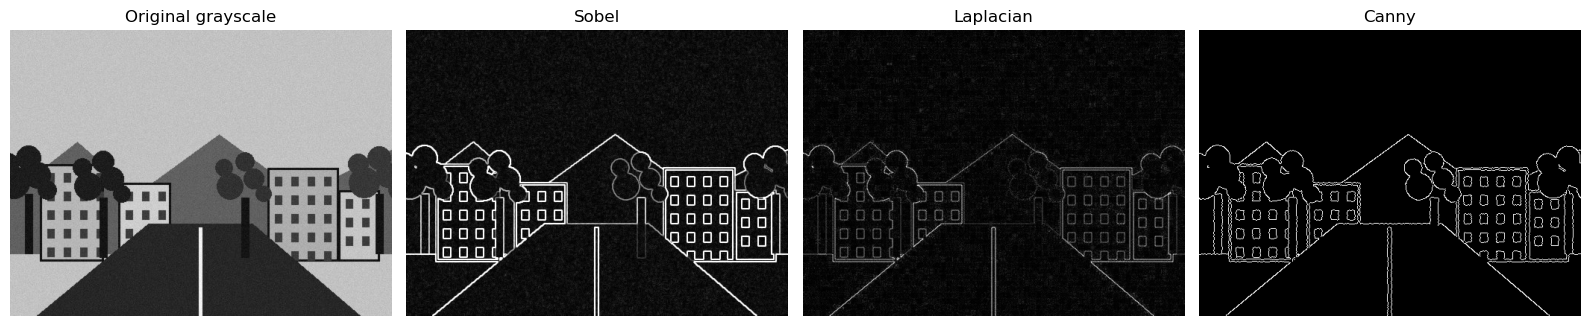

In [3]:
img1 = cv2.imread(str(IMAGE_DIR / "outdoor_scene.jpg"), cv2.IMREAD_GRAYSCALE)
if img1 is None:
    raise FileNotFoundError("Could not find images/outdoor_scene.jpg")
sx = cv2.Sobel(img1, cv2.CV_64F, 1, 0, ksize=3)
sy = cv2.Sobel(img1, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.convertScaleAbs(cv2.magnitude(sx, sy))
lap = cv2.Laplacian(img1, cv2.CV_64F)
laplacian = cv2.convertScaleAbs(lap)
canny = cv2.Canny(img1, 80, 160)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, image, title in zip(axes, [img1, sobel, laplacian, canny],
                            ["Original grayscale", "Sobel", "Laplacian", "Canny"]):
    ax.imshow(image, cmap="gray"); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

In [4]:
print("Short analysis:")
print("- Sobel highlights edges using horizontal and vertical intensity changes; it often gives thicker edges.")
print("- Laplacian responds to rapid intensity changes in all directions, but it can also amplify noise.")
print("- Canny usually gives thin, connected edges and suppresses many weak/noisy responses.")
print("For this image, Canny is often the clearest for meaningful object boundaries; the best result depends on its thresholds.")

Short analysis:
- Sobel highlights edges using horizontal and vertical intensity changes; it often gives thicker edges.
- Laplacian responds to rapid intensity changes in all directions, but it can also amplify noise.
- Canny usually gives thin, connected edges and suppresses many weak/noisy responses.
For this image, Canny is often the clearest for meaningful object boundaries; the best result depends on its thresholds.


## **Problem 2 — Noise Sensitivity Experiment**

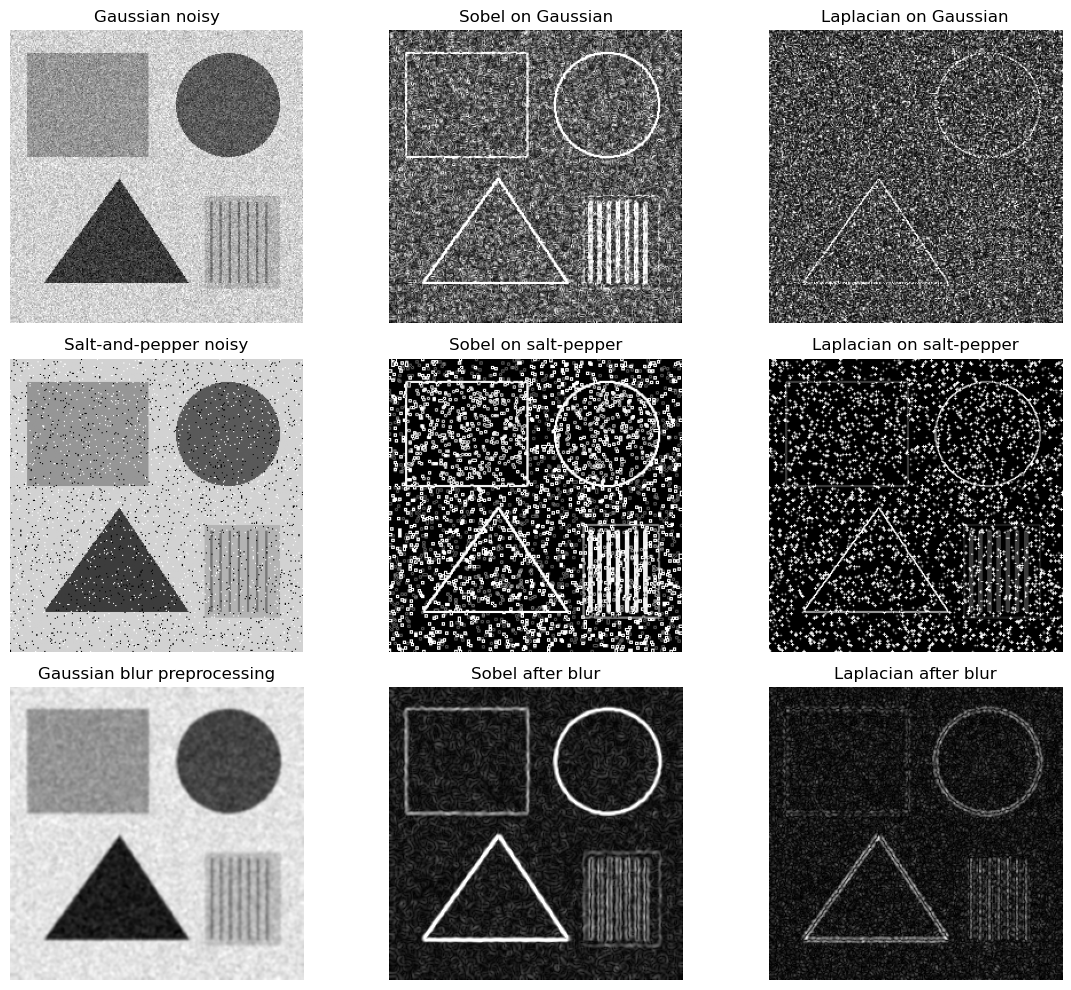

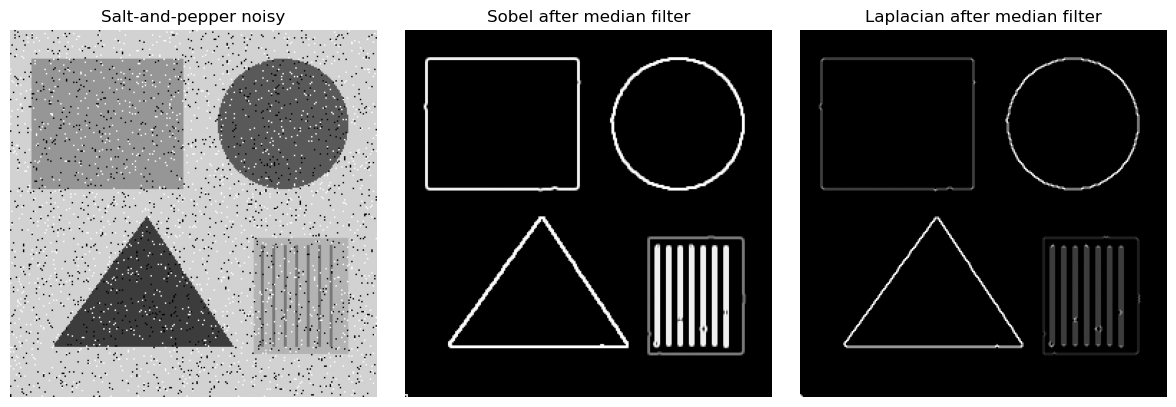

In [5]:
clean = cv2.imread(str(IMAGE_DIR / "clean_gray.png"), cv2.IMREAD_GRAYSCALE)
if clean is None:
    raise FileNotFoundError("Could not find images/clean_gray.png")
rng = np.random.default_rng(42)
gaussian_noise = np.clip(clean.astype(np.float32) + rng.normal(0, 22, clean.shape), 0, 255).astype(np.uint8)
sp_noise = clean.copy()
random_map = rng.random(clean.shape)
sp_noise[random_map < 0.025] = 0
sp_noise[random_map > 0.975] = 255

def edge_pair(image):
    sob = cv2.convertScaleAbs(cv2.magnitude(
        cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3),
        cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)))
    lap = cv2.convertScaleAbs(cv2.Laplacian(image, cv2.CV_64F))
    return sob, lap

sob_g, lap_g = edge_pair(gaussian_noise)
sob_sp, lap_sp = edge_pair(sp_noise)
blur_g = cv2.GaussianBlur(gaussian_noise, (5, 5), 1.2)
blur_sp = cv2.medianBlur(sp_noise, 3)
sob_bg, lap_bg = edge_pair(blur_g)
sob_bsp, lap_bsp = edge_pair(blur_sp)

fig, axes = plt.subplots(3, 3, figsize=(12, 10))
images = [(gaussian_noise, "Gaussian noisy"), (sob_g, "Sobel on Gaussian"), (lap_g, "Laplacian on Gaussian"),
          (sp_noise, "Salt-and-pepper noisy"), (sob_sp, "Sobel on salt-pepper"), (lap_sp, "Laplacian on salt-pepper"),
          (blur_g, "Gaussian blur preprocessing"), (sob_bg, "Sobel after blur"), (lap_bg, "Laplacian after blur")]
for ax, (image, title) in zip(axes.flat, images):
    ax.imshow(image, cmap="gray"); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, image, title in zip(axes, [sp_noise, sob_bsp, lap_bsp],
                            ["Salt-and-pepper noisy", "Sobel after median filter", "Laplacian after median filter"]):
    ax.imshow(image, cmap="gray"); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

In [6]:
print("Observations:")
print("1. Laplacian is generally more sensitive to noise because second derivatives amplify rapid pixel changes.")
print("2. Noise creates extra false edges and makes true edges less clear.")
print("3. Gaussian blur before edge detection reduces Gaussian noise.")
print("4. Median filtering is usually more effective for salt-and-pepper noise.")

Observations:
1. Laplacian is generally more sensitive to noise because second derivatives amplify rapid pixel changes.
2. Noise creates extra false edges and makes true edges less clear.
3. Gaussian blur before edge detection reduces Gaussian noise.
4. Median filtering is usually more effective for salt-and-pepper noise.


## **Problem 3 — Compression Ratio Comparison (RLE vs Huffman)**

In [7]:
gray = cv2.imread(str(IMAGE_DIR / "clean_gray.png"), cv2.IMREAD_GRAYSCALE)
if gray is None:
    raise FileNotFoundError("Could not find images/clean_gray.png")
pixels = gray.flatten().tolist()
original_bits = len(pixels) * 8

def rle_encode(values):
    if not values: return []
    result, current, count = [], values[0], 1
    for value in values[1:]:
        if value == current and count < 255:
            count += 1
        else:
            result.append((current, count)); current, count = value, 1
    result.append((current, count))
    return result

rle = rle_encode(pixels)
rle_bits = len(rle) * 16  # 8 bits for pixel value + 8 bits for run length

import heapq
from collections import Counter
def huffman_code_lengths(values):
    freq = Counter(values)
    heap = [[frequency, [[symbol, ""]]] for symbol, frequency in freq.items()]
    heapq.heapify(heap)
    if len(heap) == 1:
        return {heap[0][1][0][0]: 1}
    while len(heap) > 1:
        lo, hi = heapq.heappop(heap), heapq.heappop(heap)
        for pair in lo[1]: pair[1] = "0" + pair[1]
        for pair in hi[1]: pair[1] = "1" + pair[1]
        heapq.heappush(heap, [lo[0] + hi[0], lo[1] + hi[1]])
    return {symbol: len(code) for symbol, code in heap[0][1]}

lengths = huffman_code_lengths(pixels)
huffman_bits = sum(lengths[value] for value in pixels)
def reduction(original, compressed): return (1 - compressed / original) * 100

print(f"Original bit length: {original_bits:,} bits")
print(f"RLE encoded bit length (value + count, 8 bits each): {rle_bits:,} bits")
print(f"RLE percentage reduction: {reduction(original_bits, rle_bits):.2f}%")
print(f"Huffman encoded bit length (code payload only): {huffman_bits:,} bits")
print(f"Huffman percentage reduction: {reduction(original_bits, huffman_bits):.2f}%")

Original bit length: 524,288 bits
RLE encoded bit length (value + count, 8 bits each): 28,352 bits
RLE percentage reduction: 94.59%
Huffman encoded bit length (code payload only): 125,404 bits
Huffman percentage reduction: 76.08%


In [8]:
print("Explanation:")
print("- RLE works best when consecutive pixels repeat; long flat runs create fewer value-count pairs.")
print("- Huffman assigns shorter codes to frequent pixel values and longer codes to rare values.")
print("- These are payload estimates. A real file also stores information needed to decode it, such as run/code tables.")

Explanation:
- RLE works best when consecutive pixels repeat; long flat runs create fewer value-count pairs.
- Huffman assigns shorter codes to frequent pixel values and longer codes to rare values.
- These are payload estimates. A real file also stores information needed to decode it, such as run/code tables.


## **Problem 4 — JPEG Block Artifact Analysis**

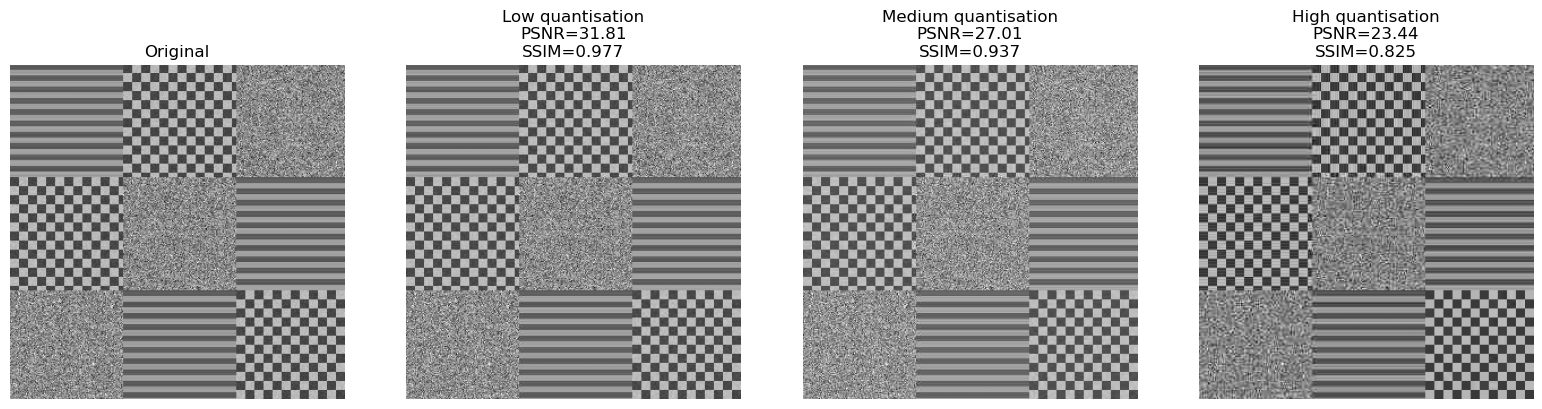

Low quantisation: scale=0.5, PSNR=31.81 dB, SSIM=0.9774
Medium quantisation: scale=1.0, PSNR=27.01 dB, SSIM=0.9369
High quantisation: scale=2.5, PSNR=23.44 dB, SSIM=0.8247


In [9]:
source = cv2.imread(str(IMAGE_DIR / "texture_scene.png"), cv2.IMREAD_GRAYSCALE)
if source is None: raise FileNotFoundError("Could not find images/texture_scene.png")
h, w = source.shape
source = source[:h - h % 8, :w - w % 8]
Q = np.array([
 [16,11,10,16,24,40,51,61], [12,12,14,19,26,58,60,55],
 [14,13,16,24,40,57,69,56], [14,17,22,29,51,87,80,62],
 [18,22,37,56,68,109,103,77], [24,35,55,64,81,104,113,92],
 [49,64,78,87,103,121,120,101], [72,92,95,98,112,100,103,99]
], dtype=np.float32)

def jpeg_style_compress(gray_image, scale):
    quant_table = np.maximum(1, np.round(Q * scale))
    padded = gray_image.astype(np.float32) - 128
    reconstructed = np.zeros_like(padded)
    for y in range(0, padded.shape[0], 8):
        for x in range(0, padded.shape[1], 8):
            block = padded[y:y+8, x:x+8]
            coeff = dct(dct(block.T, norm="ortho").T, norm="ortho")
            quantized = np.round(coeff / quant_table)
            dequantized = quantized * quant_table
            recon = idct(idct(dequantized.T, norm="ortho").T, norm="ortho")
            reconstructed[y:y+8, x:x+8] = recon
    return np.clip(reconstructed + 128, 0, 255).astype(np.uint8)

levels = [("Low quantisation", 0.5), ("Medium quantisation", 1.0), ("High quantisation", 2.5)]
results = []
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(source, cmap="gray"); axes[0].set_title("Original"); axes[0].axis("off")
for ax, (name, scale) in zip(axes[1:], levels):
    restored = jpeg_style_compress(source, scale)
    psnr = peak_signal_noise_ratio(source, restored, data_range=255)
    ssim = structural_similarity(source, restored, data_range=255)
    results.append((name, scale, restored, psnr, ssim))
    ax.imshow(restored, cmap="gray"); ax.set_title(f"{name}\nPSNR={psnr:.2f}\nSSIM={ssim:.3f}"); ax.axis("off")
plt.tight_layout(); plt.show()
for name, scale, restored, psnr, ssim in results:
    print(f"{name}: scale={scale}, PSNR={psnr:.2f} dB, SSIM={ssim:.4f}")

In [10]:
print("Analysis:")
print("- Block artifacts can appear as visible 8×8 boundaries, especially at high quantisation.")
print("- Fine textures and small details are lost because high-frequency DCT coefficients are rounded more aggressively.")
print("- Stronger quantisation generally lowers PSNR and SSIM; lower values indicate more distortion.")
print("- Exact values depend on the image and quantisation table.")

Analysis:
- Block artifacts can appear as visible 8×8 boundaries, especially at high quantisation.
- Fine textures and small details are lost because high-frequency DCT coefficients are rounded more aggressively.
- Stronger quantisation generally lowers PSNR and SSIM; lower values indicate more distortion.
- Exact values depend on the image and quantisation table.


## **Problem 5 — Texture-Based Segmentation using GLCM Features**

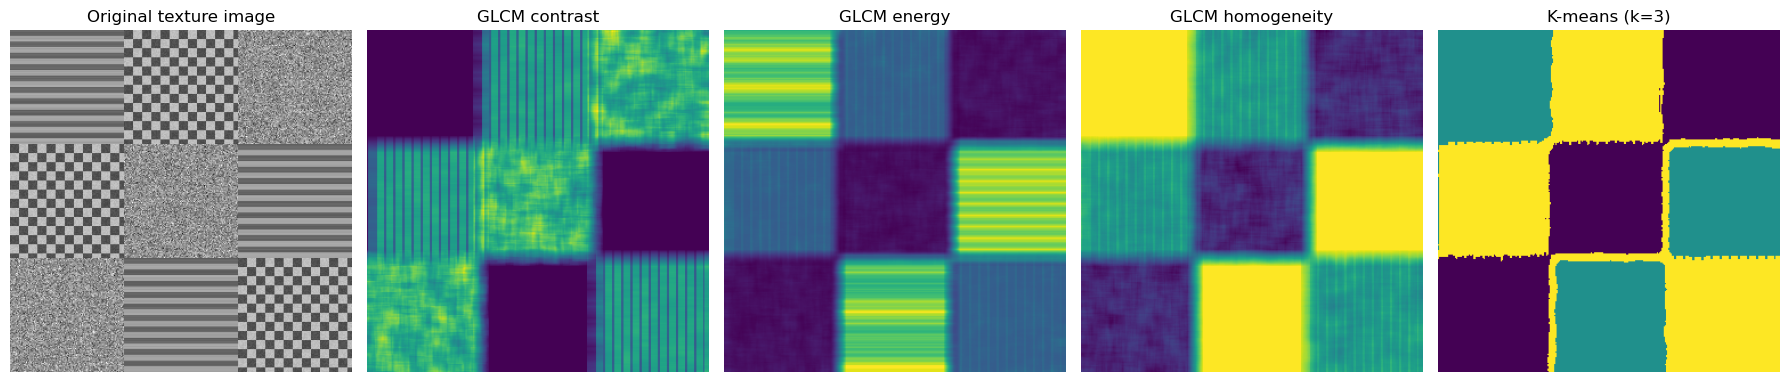

In [11]:
texture_rgb = np.array(Image.open(IMAGE_DIR / "texture_scene.png").convert("RGB"))
texture_gray = cv2.cvtColor(texture_rgb, cv2.COLOR_RGB2GRAY)
quantized = (texture_gray // 16).astype(np.uint8)
window, pad = 15, 7
padded = np.pad(quantized, pad, mode="reflect")
contrast_map = np.zeros_like(quantized, dtype=np.float32)
energy_map = np.zeros_like(quantized, dtype=np.float32)
homogeneity_map = np.zeros_like(quantized, dtype=np.float32)

# This per-neighbourhood GLCM loop may take a little time.
for y in range(quantized.shape[0]):
    for x in range(quantized.shape[1]):
        patch = padded[y:y+window, x:x+window]
        glcm = graycomatrix(patch, distances=[1], angles=[0], levels=16, symmetric=True, normed=True)
        contrast_map[y, x] = graycoprops(glcm, "contrast")[0, 0]
        energy_map[y, x] = graycoprops(glcm, "energy")[0, 0]
        homogeneity_map[y, x] = graycoprops(glcm, "homogeneity")[0, 0]

features = np.stack([contrast_map, energy_map, homogeneity_map], axis=-1)
X = features.reshape(-1, 3)
X_scaled = (X - X.mean(axis=0)) / (X.std(axis=0) + 1e-8)
labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_scaled).reshape(quantized.shape)

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, image, title in zip(axes, [texture_rgb, contrast_map, energy_map, homogeneity_map, labels],
                            ["Original texture image", "GLCM contrast", "GLCM energy", "GLCM homogeneity", "K-means (k=3)"]):
    ax.imshow(image, cmap="viridis" if title != "Original texture image" else None)
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

In [12]:
print("Observations:")
print("- Contrast is high where neighbouring pixels vary strongly.")
print("- Energy is higher for more uniform/repetitive neighbourhoods.")
print("- Homogeneity is higher when neighbouring gray levels are similar.")
print("- Combining all three features helps distinguish textures, but clusters are numeric labels, not semantic classes.")
print("- Results can improve by changing neighbourhood size, gray-level quantisation, or adding more texture features.")

Observations:
- Contrast is high where neighbouring pixels vary strongly.
- Energy is higher for more uniform/repetitive neighbourhoods.
- Homogeneity is higher when neighbouring gray levels are similar.
- Combining all three features helps distinguish textures, but clusters are numeric labels, not semantic classes.
- Results can improve by changing neighbourhood size, gray-level quantisation, or adding more texture features.


## **Problem 6 — Multi-Feature Segmentation for Disease Detection**

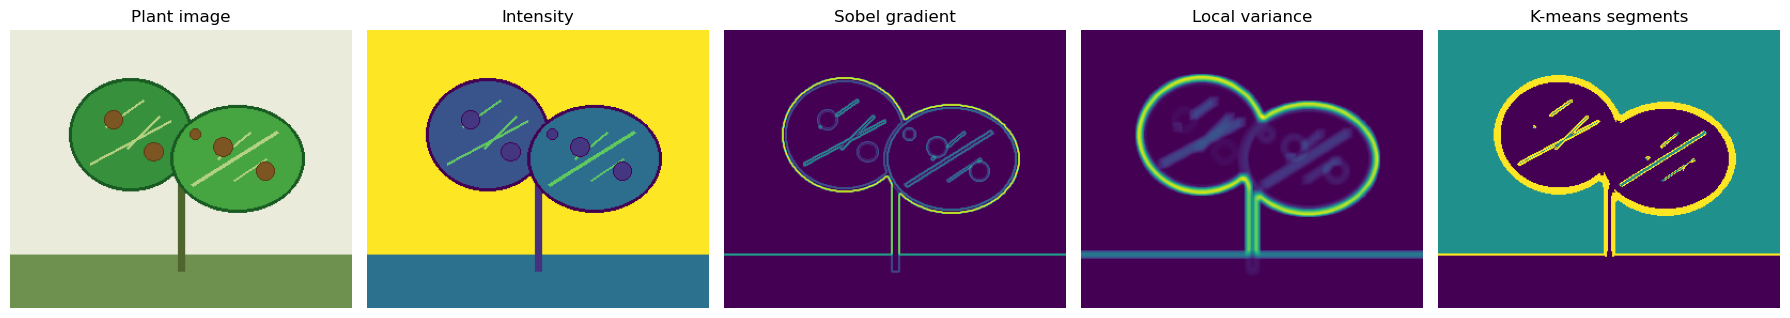

In [13]:
plant_rgb = np.array(Image.open(IMAGE_DIR / "plant_lesion_illustrative.png").convert("RGB"))
plant_gray = cv2.cvtColor(plant_rgb, cv2.COLOR_RGB2GRAY)
intensity = plant_gray.astype(np.float32) / 255.0
gx = cv2.Sobel(plant_gray, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(plant_gray, cv2.CV_32F, 0, 1, ksize=3)
gradient = cv2.magnitude(gx, gy)
gradient = gradient / (gradient.max() + 1e-8)

gray_float = intensity.astype(np.float32)
window_size = 9
local_mean = cv2.blur(gray_float, (window_size, window_size))
local_mean_sq = cv2.blur(gray_float ** 2, (window_size, window_size))
local_variance = np.maximum(local_mean_sq - local_mean ** 2, 0)
local_variance = local_variance / (local_variance.max() + 1e-8)

feature_stack = np.stack([intensity, gradient, local_variance], axis=-1)
X = feature_stack.reshape(-1, 3)
X_scaled = (X - X.mean(axis=0)) / (X.std(axis=0) + 1e-8)
segments = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_scaled).reshape(plant_gray.shape)

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, image, title in zip(axes, [plant_rgb, intensity, gradient, local_variance, segments],
                            ["Plant image", "Intensity", "Sobel gradient", "Local variance", "K-means segments"]):
    ax.imshow(image, cmap="viridis" if title != "Plant image" else None)
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

In [14]:
print("Evaluation / observations:")
print("- Intensity can help separate dark brown lesions from brighter green leaf areas, but shadows can look similar to lesions.")
print("- Gradient magnitude highlights boundaries and spots, but it does not identify disease by itself.")
print("- Local variance captures texture differences; irregular lesion areas may have different texture from healthy leaf regions.")
print("- Misclassifications can occur due to lighting, shadows, leaf veins, background pixels, and overlap between feature values.")
print("- K-means cluster numbers have no inherent meaning. Inspect clusters before describing one as diseased or healthy.")

Evaluation / observations:
- Intensity can help separate dark brown lesions from brighter green leaf areas, but shadows can look similar to lesions.
- Gradient magnitude highlights boundaries and spots, but it does not identify disease by itself.
- Local variance captures texture differences; irregular lesion areas may have different texture from healthy leaf regions.
- Misclassifications can occur due to lighting, shadows, leaf veins, background pixels, and overlap between feature values.
- K-means cluster numbers have no inherent meaning. Inspect clusters before describing one as diseased or healthy.


## **Conclusion**
1. Canny often produces clearer connected edges than Sobel or Laplacian.
2. Derivative-based edge detectors are sensitive to noise; Gaussian or median filtering can help.
3. RLE benefits from repeated runs, while Huffman coding benefits from frequent symbols.
4. Strong JPEG-style quantisation reduces detail and generally lowers PSNR and SSIM.
5. GLCM texture features and multi-feature K-means segmentation group similar local patterns, but results depend on feature choices and image conditions.